# Resection Mask Segmentation — RAMPS Pipeline

**We will generate a pre-operative resection mask using [RAMPS](https://github.com/cnnp-lab/RAMPS) (Resections And Masks in Preoperative Space), the pipeline from Simpson, Hall, Duncan, Wang & Taylor, *Imaging Neuroscience* 3 (2025), [doi:10.1162/IMAG.a.147](https://doi.org/10.1162/IMAG.a.147). Please set up RAMPS following their instructions before continuing.**

RAMPS registers a patient's post-operative T1w scan onto their pre-operative T1w scan and isolates the resection cavity directly in pre-operative space — this avoids the alignment problems that post-operative sagging/swelling cause for masks drawn in post-op space instead.

## How to set up RAMPS

RAMPS needs its own environment, separate from `mindmap`: it pins Python 3.8 and TensorFlow 2.13 (which itself requires numpy<2), which would conflict with `mindmap`'s own numpy 2.x stack.

```bash
# 1. dedicated environment + the pipeline itself
conda create -n RAMPenv python=3.8.20
conda activate RAMPenv
git clone https://github.com/cnnp-lab/RAMPS.git /home/nino/Softwares/RAMPS
cd /home/nino/Softwares/RAMPS
pip install -r requirements.txt   # drop the tensorflow-macos line first if on Linux

# 2. FreeSurfer (>=7.3, for SynthStrip) - already installed on this machine
export FREESURFER_HOME=/home/nino/Softwares/freesurfer
source $FREESURFER_HOME/SetUpFreeSurfer.sh

# 3. SynthSeg, cloned *inside* RAMPS, plus its model weights
cd Place_SynthSeg_here
git clone https://github.com/BBillot/SynthSeg.git
# then place synthseg_{1.0,2.0,parc_2.0,qc_2.0,robust_2.0}.h5 in SynthSeg/models/
# (FreeSurfer already ships all five under $FREESURFER_HOME/models/ - copying them
# across is easier than the original, now-broken SynthSeg download link)
```

## Running it from the command line

```bash
python RAMP.py <pre-op.nii.gz> <post-op.nii.gz> <output_folder> <subject_id> <hemisphere L|R> <lobe T|F|O|P>
```

All six positional arguments are required by this version of the script. `<lobe>` can combine several letters (e.g. `TF` for temporal+frontal); RAMPS folds the subcortical and insula regions into `T`.

Since RAMPS lives in its own environment, the cells below call it as a **subprocess** rather than importing it - it has no importable Python API of its own.

## 🧪 - Experiment setup

In [1]:
import subprocess
from pathlib import Path

import ants
import nibabel as nib
import numpy as np

import mindmap as mm

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "spike11"

# data - pre/post T1w (non-BIDS-conform, resolved through the 't1w' datatype)
pre_t1  = dm.get_path(sub, "t1w", session="preop", res="cmp")
post_t1 = dm.get_path(sub, "t1w", session="postop", space="individual", desc="brain")

print("pre-op :", pre_t1)
print("post-op:", post_t1)

pre-op : /home/nino/Code/mindmap/data/sub-spike11/ses-preop/anat/sub-spike11_ses-preop_res-cmp_T1w.nii.gz
post-op: /home/nino/Code/mindmap/data/sub-spike11/ses-postop/anat/sub-spike11_ses-postop_space-individual_desc-brain_T1w.nii.gz


## 🔎 - Hemisphere and lobe of resection

RAMPS accepts the hemisphere and lobe of resection to narrow its search, and the paper's own
benchmarks show this consistently improves accuracy over letting RAMPS search the whole brain.
`spike11` already has a manually-drawn resection mask in this dataset (used elsewhere as the
ground truth for evaluation) - we can determine both from it directly, by checking which regions
of a parcellation atlas it overlaps most, rather than guessing.

In [2]:
# both live directly under the mindmap derivatives folder - no dedicated `dm` accessor for these
man_mask_path = dm.roots["mm"] / f"sub-{sub}" / "resec" / f"sub-{sub}_man-seg.nii.gz"
parc_path     = dm.roots["mm"] / f"sub-{sub}" / "parc" / f"sub-{sub}_multiConn4-dseg.nii.gz"
parc_lut_path = parc_path.with_suffix("").with_suffix(".txt")

man_mask = nib.load(man_mask_path)
parc     = nib.load(parc_path)

# the two images aren't on the same voxel grid - map mask voxels into the parcellation's
# grid via world (RAS) coordinates rather than assuming matching indices
vox_mask  = np.argwhere(man_mask.get_fdata() > 0)
world     = nib.affines.apply_affine(man_mask.affine, vox_mask)
vox_parc  = np.round(nib.affines.apply_affine(np.linalg.inv(parc.affine), world)).astype(int)
in_bounds = np.all((vox_parc >= 0) & (vox_parc < np.array(parc.shape)), axis=1)
vox_parc  = vox_parc[in_bounds]

labels = parc.get_fdata()[vox_parc[:, 0], vox_parc[:, 1], vox_parc[:, 2]].astype(int)

lut = {}
with open(parc_lut_path) as f:
    for line in f:
        parts = line.split()
        if len(parts) >= 2 and parts[0].isdigit():
            lut[int(parts[0])] = parts[1]

vals, counts = np.unique(labels, return_counts=True)
for v, c in sorted(zip(vals, counts), key=lambda x: -x[1])[:8]:
    print(f"{c:6d}  {lut.get(int(v), '???')}")

 16708  ???
  1992  ctx-rh-temporalpole_1
  1756  ctx-rh-entorhinal_1
  1143  ctx-rh-inferiortemporal_1
  1117  subc-rh-amygdala
  1082  ctx-rh-superiortemporal_11
   853  ctx-rh-fusiform_8
   733  subc-rh-accumbens_area


In [3]:
# dominated by ctx-rh-temporalpole / entorhinal / fusiform / middletemporal + subc-rh-amygdala:
# a right anterior temporal lobe resection - the most common epilepsy surgery, and what most of
# RAMPS' own validation cohort consists of too.
hemisphere = "R"
lobe       = "T"  # RAMPS folds subcortical + insula regions into "T" as well

## 🧬 - Data Processing
Run the RAMPS pipeline. This runs 14 steps - resampling, bias correction, skull-stripping and
lobe segmentation for both images, ANTs registration of post-op onto pre-op, then cavity
classification and cleanup - and takes on the order of 15-20 minutes on CPU. It's re-run only if
the final mask isn't already on disk.

In [4]:
output_dir = dm.roots["mm"].parent / "ramps" / f"sub-{sub}"
output_dir.mkdir(parents=True, exist_ok=True)

mask_path = output_dir / "RAMPS_Resection_Mask_Output" / "RAMP_The_resection_mask_in_PRE.nii.gz"

ramps_script      = "/home/nino/Softwares/RAMPS/RAMP.py"
freesurfer_home    = "/home/nino/Softwares/freesurfer"

if not mask_path.exists():
    cmd = f"""
    source ~/miniconda3/etc/profile.d/conda.sh
    conda activate RAMPenv
    export FREESURFER_HOME={freesurfer_home}
    source $FREESURFER_HOME/SetUpFreeSurfer.sh > /dev/null
    python {ramps_script} {pre_t1} {post_t1} {output_dir} {sub} {hemisphere} {lobe}
    """
    result = subprocess.run(["bash", "-c", cmd], capture_output=True, text=True)
    print(result.stdout[-3000:])
    if result.returncode != 0:
        print("STDERR:\n", result.stderr[-3000:])
else:
    print(f"Mask already computed at {mask_path}")

Mask already computed at /home/nino/Code/mindmap/data/derivatives/ramps/sub-spike11/RAMPS_Resection_Mask_Output/RAMP_The_resection_mask_in_PRE.nii.gz


## 📊 - Visualization
The mask RAMPS actually wants you to use is `RAMPS_Resection_Mask_Output/RAMP_The_resection_mask_in_PRE.nii.gz`
- resampled back to the pre-op image's original resolution. That folder also has the pre/post
images re-registered into pre-op space, useful for checking the alignment RAMPS computed.

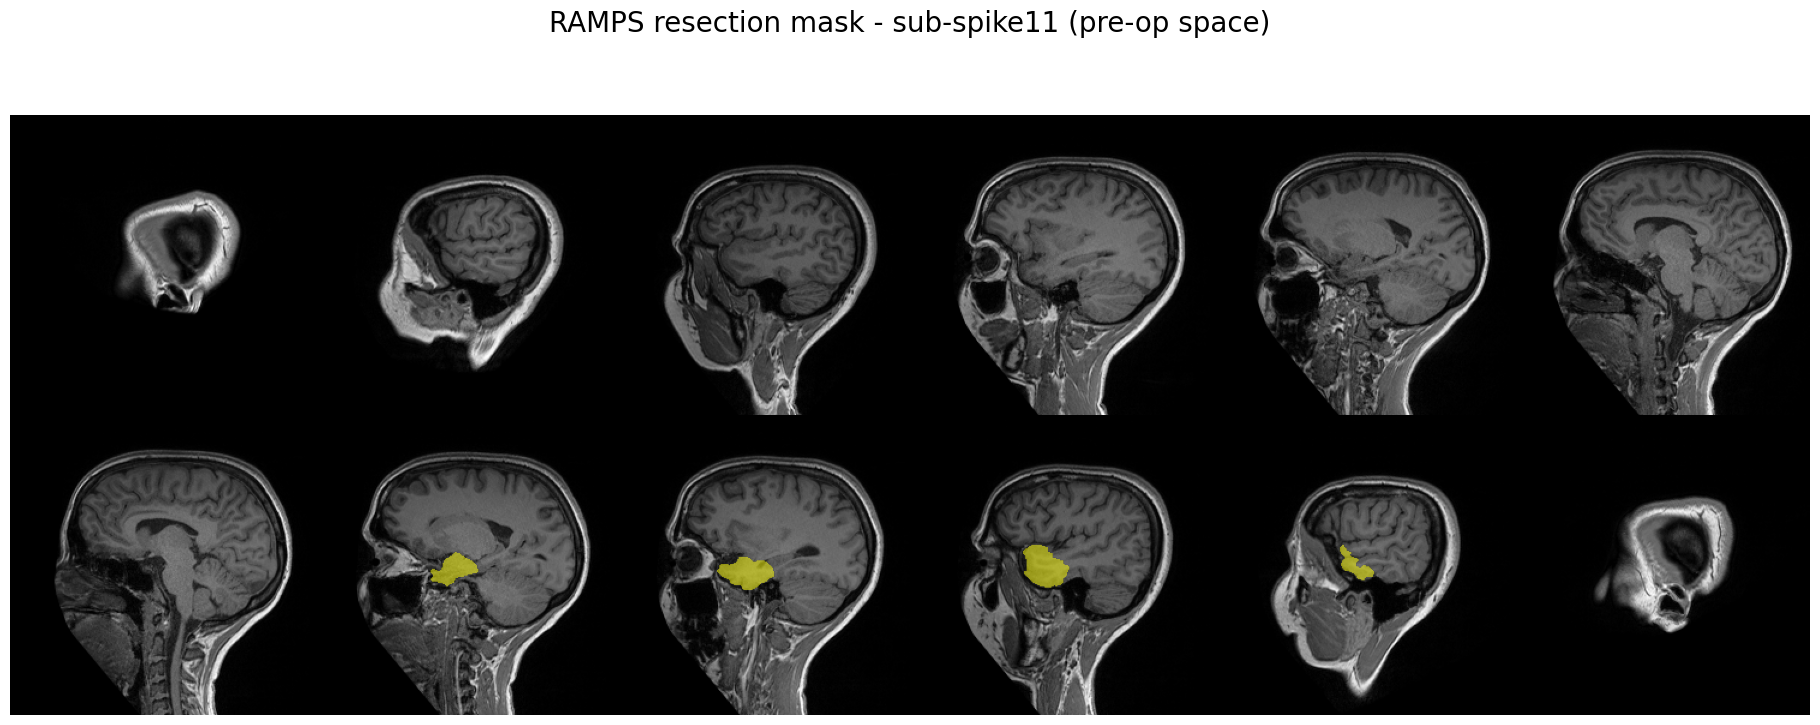

In [5]:
pre_op_img = ants.image_read(str(pre_t1))
ramps_mask = ants.image_read(str(mask_path))

pre_op_img.plot(
    overlay=ramps_mask, overlay_alpha=0.5, overlay_cmap="autumn",
    ncol=6, figsize=3, title=f"RAMPS resection mask - sub-{sub} (pre-op space)",
)

## 🎯 - Evaluation
The paper validates RAMPS against manually-drawn masks using the Dice similarity coefficient
(0: no overlap, 1: perfect overlap; >0.8 is considered excellent). `spike11` already has one, so
we can check the same way here.

In [6]:
def dice(a, b):
    a, b = a.astype(bool), b.astype(bool)
    return 2 * np.logical_and(a, b).sum() / (a.sum() + b.sum())

# resample the manual mask onto the RAMPS mask's grid before comparing voxel-for-voxel
# ('genericLabel' is ants' recommended interpolation for label/mask images)
man_mask_on_ramps_grid = ants.resample_image_to_target(
    ants.image_read(str(man_mask_path)), ramps_mask, interp_type="genericLabel"
).numpy()

dsc = dice(ramps_mask.numpy(), man_mask_on_ramps_grid)
print(f"Dice similarity coefficient vs. the manual mask: {dsc:.2f}")

Dice similarity coefficient vs. the manual mask: 0.50


As with every automated pipeline in this space, RAMPS' authors recommend visually inspecting
every generated mask before using it - RAMPS masks run slightly larger than manual ones on
average, so a quick check against the overlay above is worth doing rather than trusting the
Dice score alone.